# LAB 06 — Attention Mechanism
**IMDb 10.000 reviews, cùng split Lab 5; seed 2026.**
Họ tên: [Tự điền] — MSSV: [Tự điền]. Hạn nộp W6: 23:59 ngày 28/10/2026.

NumPy core không gọi framework attention. Classifier single-head tự tính QKᵀ, softmax và AV bằng PyTorch.
Bảng/plot trực tiếp; ảnh trong data; bảng kết quả gộp results.csv.
Nhận xét tiếng Việt và worksheet là bản tham khảo AI cần người học kiểm tra.



In [1]:
from pathlib import Path
import json,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import ConfusionMatrixDisplay,confusion_matrix,classification_report
from attention_numpy import stable_softmax,scaled_dot_product_attention,entropy
from preprocessing import SEED,load_data,tokenize,build_vocabulary,encode_batch,retention
from attention_models import (EMBED_DIM,HIDDEN_DIM,BATCH_SIZE,LEARNING_RATE,EPOCHS,DROPOUT,
    set_seed,fit_sequence,predict_sequence,metric_row,metrics)
from analysis_utils import trace_attention,token_table,select_examples,occlude_token
ROOT=Path.cwd()
saved_cells=json.loads((ROOT/"self_attention.ipynb").read_text(encoding="utf-8"))["cells"]
case_cells=[c for c in saved_cells if c["cell_type"]=="markdown" and c.get("metadata",{}).get("case_id")]
case_discussions={c["metadata"]["case_id"]:"".join(c["source"]) for c in case_cells}
case_categories={c["metadata"]["case_id"]:c["metadata"]["category"] for c in case_cells}
error_report_sections=["".join(c["source"]) for c in saved_cells
    if c["cell_type"]=="markdown" and c.get("metadata",{}).get("discussion_key","").startswith("error_")]
(ROOT/"data").mkdir(exist_ok=True)
set_seed()
records=[]
def table(value):
    frame=value if isinstance(value,pd.DataFrame) else pd.DataFrame(value)
    print(frame.round(5).to_string(index=False,max_rows=None,max_cols=None))
def figure(name):
    plt.tight_layout()
    plt.gcf().savefig(ROOT/"data"/name,dpi=160,bbox_inches="tight")
    plt.show()
def heatmap(ax,A,tokens,title):
    im=ax.imshow(A,cmap="Blues",aspect="auto",vmin=0)
    ticks=list(range(0,len(tokens),max(1,int(np.ceil(len(tokens)/20)))))
    ax.set_xticks(ticks,[f"{i}:{tokens[i]}" for i in ticks],rotation=60,ha="right",fontsize=8)
    ax.set_yticks(ticks,[f"{i}:{tokens[i]}" for i in ticks],fontsize=8)
    ax.set_xlabel("Key / value position");ax.set_ylabel("Query position");ax.set_title(title)
    return im
plt.rcParams.update({"figure.dpi":110})
print("Seed",SEED,"| PyTorch",torch.__version__,"| CPU threads",torch.get_num_threads())

Seed 2026 | PyTorch 2.14.1+cpu | CPU threads 4


## 13–14. Scaling và bài tính
Chia QKᵀ cho sqrt(d_k) giúp kiểm soát độ lớn score khi dimensions tăng.
Với [4,2,0], d_k=4: scaled scores=[2,1,0]. So sánh entropy/weights bên dưới.
Scaling là rescale logits trước softmax, không phải biến dot product thành cosine similarity.

In [2]:
scaling_rows=[]
for scaled in [False,True]:
    scores=np.array([4.,2.,0.])/(2 if scaled else 1)
    weights=stable_softmax(scores)
    for i,(s,w) in enumerate(zip(scores,weights)):
        scaling_rows.append({"record_type":"scaling_example","scaled":scaled,"position":i,
                             "score":s,"attention":w,"entropy_nats":float(entropy(weights))})
table(scaling_rows);records.extend(scaling_rows)

    record_type  scaled  position  score  attention  entropy_nats
scaling_example   False         0    4.0    0.86681       0.44106
scaling_example   False         1    2.0    0.11731       0.44106
scaling_example   False         2    0.0    0.01588       0.44106
scaling_example    True         0    2.0    0.66524       0.83240
scaling_example    True         1    1.0    0.24473       0.83240
scaling_example    True         2    0.0    0.09003       0.83240



### Nhận xét — Scaling thay đổi phân phối attention

Với scores [4, 2, 0], softmax không scaling cho weights khoảng [0,86681; 0,11731; 0,01588]. Phần tử đầu chi phối tổng hợp context. Sau khi chia scores cho sqrt(d_k)=2, weights thành [0,66524; 0,24473; 0,09003]: phần tử đầu vẫn đứng đầu nhưng hai values còn lại đóng góp lớn hơn.

Entropy tăng từ **0,44106 lên 0,83240 nats**, phù hợp với phân phối bớt tập trung. Scaling không đổi thứ tự scores vì chia cho một số dương. Nó điều chỉnh thang logits, không chuẩn hóa query/key thành vector đơn vị hay biến dot product thành cosine similarity.

Weights bớt tập trung chưa đủ để kết luận representation tốt hơn. Chất lượng còn phụ thuộc dữ liệu, values và objective; ý nghĩa chính của ví dụ này là quan sát ảnh hưởng số học của scaling.

## 15. Temperature
Dùng cùng scores [1,2,3] và T=0.5/1/2. Entropy sử dụng log tự nhiên, đơn vị nats.
Temperature thấp làm distribution tập trung; cao làm phẳng hơn khi scores không bằng nhau.

record_type  temperature  max_weight  entropy_nats  weight_1  weight_2  weight_3
temperature          0.5     0.86681       0.44106   0.01588   0.11731   0.86681
temperature          1.0     0.66524       0.83240   0.09003   0.24473   0.66524
temperature          2.0     0.50648       1.02019   0.18632   0.30720   0.50648


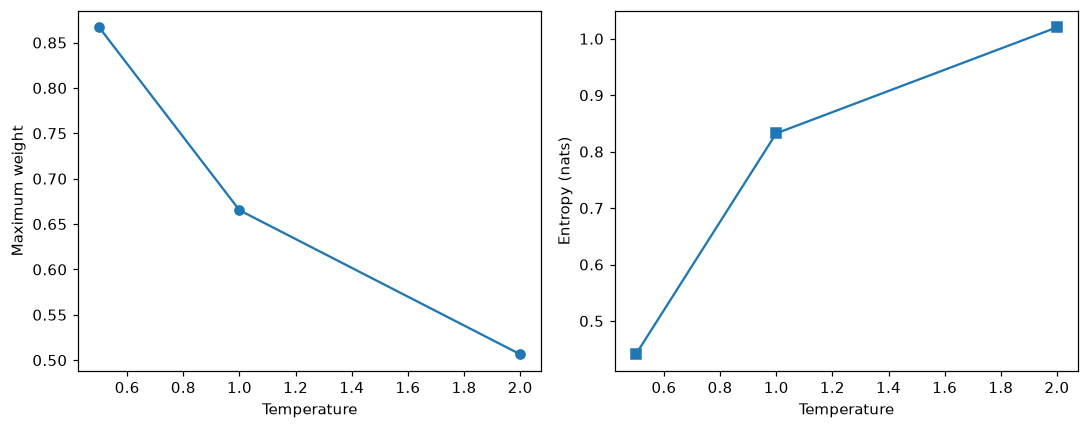

In [3]:
temperature_rows=[]
for temperature in [.5,1.,2.]:
    weights=stable_softmax(np.array([1.,2.,3.])/temperature)
    temperature_rows.append({"record_type":"temperature","temperature":temperature,
        "max_weight":float(weights.max()),"entropy_nats":float(entropy(weights)),
        "weight_1":weights[0],"weight_2":weights[1],"weight_3":weights[2]})
table(temperature_rows);records.extend(temperature_rows)
fig,axes=plt.subplots(1,2,figsize=(10,4))
frame=pd.DataFrame(temperature_rows)
axes[0].plot(frame.temperature,frame.max_weight,marker="o");axes[0].set_ylabel("Maximum weight")
axes[1].plot(frame.temperature,frame.entropy_nats,marker="s");axes[1].set_ylabel("Entropy (nats)")
for ax in axes:ax.set_xlabel("Temperature")
figure("temperature.png")

### Nhận xét — Temperature và entropy

| Temperature | Weight lớn nhất | Entropy (nats) |
|---|---:|---:|
| 0,5 | 0,86681 | 0,44106 |
| 1,0 | 0,66524 | 0,83240 |
| 2,0 | 0,50648 | 1,02019 |

Temperature 0,5 khuếch đại chênh lệch scores nên phần tử thứ ba nhận gần 87% trọng số. Temperature 2 làm chênh lệch nhỏ hơn và phân phối đều hơn. Entropy tăng phản ánh sự phân tán này; entropy cực đại với ba phần tử là ln(3)≈1,09861.

Temperature dương không đảo thứ tự weights. Nó điều chỉnh mức tập trung thay vì tự đổi token đứng đầu. Temperature thấp có thể khuếch đại một score chưa phù hợp; temperature cao giữ nhiều thông tin hơn nhưng cũng có thể làm loãng tín hiệu cần thiết.

## 16. Core implementation — scaled_dot_product_attention
attention_numpy.py tự tính scores=QKᵀ/sqrt(d_k), row-softmax, context=weights@V.
Q/K/V là ma trận 2D; trả về ba ma trận scores, weights, context.
Có temperature và optional mask=True cho vị trí được phép; fully masked row báo lỗi thay vì trả NaN.
Không dùng MultiheadAttention/keras.layers.Attention hoặc built-in attention trong core và classifier.

## 17. Numerical stability — test bắt buộc
Softmax trừ max theo từng hàng. Hệ số exp(-max) xuất hiện ở cả tử và mẫu nên triệt tiêu.
Điều này tránh overflow khi x=[1000,1001,1002].

In [4]:
q=np.array([[1.,2.]])
K=np.array([[1.,0.],[0.,1.],[1.,1.]])
V=np.array([[1.,0.],[0.,1.],[2.,2.]])
scores,A,C=scaled_dot_product_attention(q,K,V)
print("Scaled scores:");table(scores)
print("Weights:");table(A)
print("Context:");table(C)
print("Row sums:",A.sum(axis=-1))
large=stable_softmax(np.array([1000.,1001.,1002.]))
small=stable_softmax(np.array([1.,2.,3.]))
table([{"position":i,"stable_large":large[i],"reference":small[i],
        "absolute_difference":abs(large[i]-small[i])} for i in range(3)])
print("Stable finite:",np.isfinite(large).all(),"| sum:",large.sum())
for i,w in enumerate(large):
    records.append({"record_type":"numerical_stability","position":i,"attention":w,"reference":small[i]})
for i in range(K.shape[0]):
    records.append({"record_type":"numpy_core","position":i,"score":scores[0,i],"attention":A[0,i]})
for i,value in enumerate(C[0]):
    records.append({"record_type":"numpy_core_context","component":i,"value":value})

Scaled scores:
      0       1       2
0.70711 1.41421 2.12132
Weights:
      0     1       2
0.14003 0.284 0.57598
Context:
      0       1
1.29198 1.43595
Row sums: [1.]
 position  stable_large  reference  absolute_difference
        0       0.09003    0.09003                  0.0
        1       0.24473    0.24473                  0.0
        2       0.66524    0.66524                  0.0
Stable finite: True | sum: 0.9999999999999999


### Nhận xét — Core attention và tính ổn định số

Query [1, 2] tạo raw scores [1, 2, 3] với ba keys. Sau scaling theo sqrt(2), key thứ ba vẫn có weight lớn nhất. Context là tổng có trọng số các values, nên value thứ ba [2, 2] ảnh hưởng mạnh tới cả hai tọa độ đầu ra. Đây là weighted combination, không phải chọn duy nhất một value.

Softmax được tính **theo từng hàng query**. Tổng weights mỗi hàng bằng 1; với nhiều queries, không yêu cầu tổng toàn bộ matrix bằng 1.

Với [1000, 1001, 1002], phép trừ maximum tạo [-2, -1, 0] trước khi lấy exponential. Kết quả hữu hạn [0,09003; 0,24473; 0,66524] trùng softmax của [1, 2, 3]. Hệ số exponential chung triệt tiêu giữa tử và mẫu nên phép dịch bảo toàn kết quả, đồng thời tránh overflow.

### Bổ sung: dimension và softmax concentration
Monte Carlo seed 2026, 256 independent queries, 32 keys/query, d_k=4/16/64/256.
Các entries Gaussian chuẩn; so sánh raw/scaled score std, max weight và entropy trung bình.
Đây là kiểm tra số học trên vectors ngẫu nhiên, không phải thí nghiệm ngữ nghĩa.

In [5]:
rng=np.random.default_rng(SEED)
dimension_rows=[]
for dimension in [4,16,64,256]:
    queries=rng.normal(size=(256,dimension))
    keys=rng.normal(size=(256,32,dimension))
    raw=np.einsum("bd,bnd->bn",queries,keys)
    for scaled in [False,True]:
        scores=raw/(np.sqrt(dimension) if scaled else 1)
        weights=stable_softmax(scores)
        dimension_rows.append({"record_type":"dimension_scaling","dimension":dimension,"scaled":scaled,
            "score_std":float(scores.std()),"mean_max_weight":float(weights.max(axis=1).mean()),
            "mean_entropy_nats":float(entropy(weights).mean())})
table(dimension_rows);records.extend(dimension_rows)

      record_type  dimension  scaled  score_std  mean_max_weight  mean_entropy_nats
dimension_scaling          4   False    2.03362          0.34521            2.24900
dimension_scaling          4    True    1.01681          0.15927            3.01997
dimension_scaling         16   False    3.92059          0.63321            1.12763
dimension_scaling         16    True    0.98015          0.16632            3.01634
dimension_scaling         64   False    8.04671          0.81729            0.50214
dimension_scaling         64    True    1.00584          0.16297            3.01282
dimension_scaling        256   False   15.73889          0.89315            0.26083
dimension_scaling        256    True    0.98368          0.15630            3.03743



### Nhận xét — Dimension lớn khiến softmax tập trung ra sao?

Trong thí nghiệm Gaussian, dimension tăng 4→256 làm raw score standard deviation tăng khoảng **2,03→15,74**. Weight lớn nhất trung bình tăng **0,345→0,893**, trong khi entropy giảm **2,249→0,261 nats**. Softmax trở nên tập trung mạnh dù vectors chỉ được lấy ngẫu nhiên.

Sau khi chia sqrt(d_k), score standard deviation quanh 1, max weight trung bình quanh 0,16 và entropy quanh 3 nats. Điều này phù hợp giả thiết các thành phần độc lập: variance của dot product tăng theo dimension nên chia căn bậc hai giúp giữ variance ở thang ổn định hơn.

Quan sát hỗ trợ lý do số học của scaling. Nó chưa đánh giá token nào quan trọng về ngữ nghĩa, và cùng một entropy không nhất thiết tối ưu cho mọi task.

## 18. Experiment 1 — Attention distribution
Sequence: The movie was surprisingly good despite a very slow beginning.
Dùng keys/values bốn chiều **gán tay để minh họa**, không phải embeddings đã học.
Các trục minh họa positive/negative/topic/time; q_sentiment=[1,1,0,0].
Đặt tên trục/query chỉ là giả định của toy example, không chứng minh model tự hiểu sentiment.

record_type     query        token  position  score  attention
  toy_query sentiment          the         0   0.05    0.07607
  toy_query sentiment        movie         1   0.10    0.07997
  toy_query sentiment          was         2   0.05    0.07607
  toy_query sentiment surprisingly         3   0.30    0.09767
  toy_query sentiment         good         4   1.00    0.19668
  toy_query sentiment      despite         5   0.05    0.07607
  toy_query sentiment            a         6   0.05    0.07607
  toy_query sentiment         very         7   0.05    0.07607
  toy_query sentiment         slow         8   0.85    0.16929
  toy_query sentiment    beginning         9   0.05    0.07607
Context: [[0.46921516 0.33217462 0.21153423 0.1331148 ]]


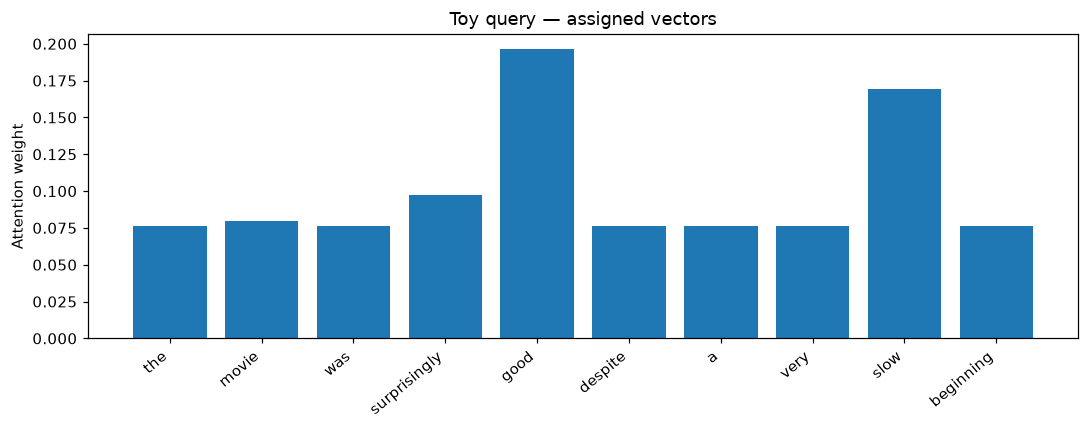

In [6]:
toy_tokens=tokenize("The movie was surprisingly good despite a very slow beginning.")
toy_map={w:np.array([.05,.05,.05,.05]) for w in toy_tokens}
toy_map.update({"good":np.array([2.,0.,0.,0.]),"slow":np.array([0.,1.7,0.,0.]),
    "movie":np.array([.1,.1,2.,0.]),"surprisingly":np.array([.5,.1,.1,0.]),
    "beginning":np.array([0.,.1,.3,1.5])})
toy_X=np.array([toy_map[w] for w in toy_tokens])
query_sentiment=np.array([[1.,1.,0.,0.]])
s_sent,a_sent,c_sent=scaled_dot_product_attention(query_sentiment,toy_X,toy_X)
toy_rows=[{"record_type":"toy_query","query":"sentiment","token":word,"position":i,
           "score":s_sent[0,i],"attention":a_sent[0,i]} for i,word in enumerate(toy_tokens)]
table(toy_rows);records.extend(toy_rows)
print("Context:",c_sent)
plt.figure(figsize=(10,4));plt.bar(toy_tokens,a_sent[0])
plt.xticks(rotation=40,ha="right");plt.ylabel("Attention weight");plt.title("Toy query — assigned vectors")
figure("toy_attention.png")

### Nhận xét — Phân phối attention với query giả lập

Với câu *The movie was surprisingly good despite a very slow beginning*, query sentiment=[1, 1, 0, 0] sử dụng hai thành phần đầu của keys. Token **good** có scaled score 1, còn **slow** có score 0,85; cả hai nhận weights cao hơn những từ có score nhỏ. Các values còn lại vẫn tham gia context vì weights của chúng không bằng 0.

Attention có thể giữ đồng thời thông tin tích cực và tiêu cực. Một weight lớn không tự quyết định sentiment toàn câu: còn phải xem nội dung value và classifier. Weight cao ở slow có thể giúp giữ tín hiệu chê, không có nghĩa dự đoán là positive.

Vectors/query được gán tay để làm rõ phép tính, nên hình phản ánh thiết kế của ví dụ minh họa. Phần heatmap của classifier đã huấn luyện phía sau mới sử dụng embeddings và Q/K/V học từ IMDb.

## 19. Experiment 2 — Query thay đổi
Giữ nguyên keys/values, đổi q_topic=[0,0,1,0]. Attention phụ thuộc query, không phải danh sách từ quan trọng cố định.

record_type query        token  position  score  attention
  toy_query topic          the         0  0.025    0.08503
  toy_query topic        movie         1  1.000    0.22543
  toy_query topic          was         2  0.025    0.08503
  toy_query topic surprisingly         3  0.050    0.08718
  toy_query topic         good         4  0.000    0.08293
  toy_query topic      despite         5  0.025    0.08503
  toy_query topic            a         6  0.025    0.08503
  toy_query topic         very         7  0.025    0.08503
  toy_query topic         slow         8  0.000    0.08293
  toy_query topic    beginning         9  0.150    0.09635


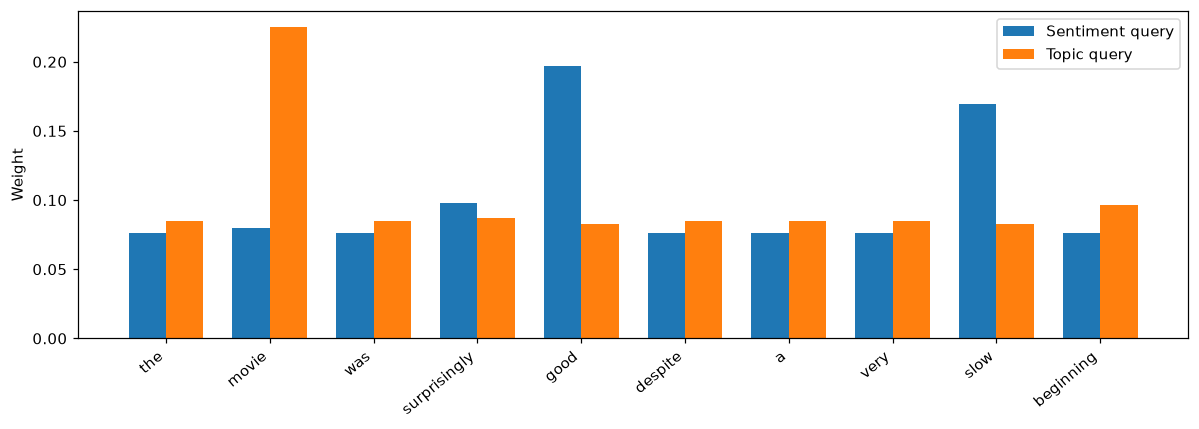

In [7]:
query_topic=np.array([[0.,0.,1.,0.]])
s_topic,a_topic,c_topic=scaled_dot_product_attention(query_topic,toy_X,toy_X)
query_rows=[{"record_type":"toy_query","query":"topic","token":word,"position":i,
    "score":s_topic[0,i],"attention":a_topic[0,i]} for i,word in enumerate(toy_tokens)]
table(query_rows);records.extend(query_rows)
fig,ax=plt.subplots(figsize=(11,4))
positions=np.arange(len(toy_tokens))
ax.bar(positions-.18,a_sent[0],width=.36,label="Sentiment query")
ax.bar(positions+.18,a_topic[0],width=.36,label="Topic query")
ax.set_xticks(positions,toy_tokens,rotation=40,ha="right");ax.set_ylabel("Weight");ax.legend()
figure("query_comparison.png")

### Nhận xét — Đổi query làm thay đổi thông tin được tổng hợp

Với query topic=[0, 0, 1, 0], **movie** nhận attention lớn nhất vì thành phần thứ ba của key này cao. Query sentiment lại ưu tiên **good** qua hai trục đầu. Keys/values được giữ nguyên nên khác biệt bắt nguồn từ query.

Ví dụ cho thấy attention không phải danh sách từ quan trọng cố định. Cùng văn bản có thể cần những phân phối weights khác nhau tùy thông tin muốn tìm. Đổi query làm weighted sum các values thay đổi, vì vậy context vector cũng có thể nhấn mạnh nội dung khác.

Sentiment/topic là tên mô tả queries do người thiết kế đặt trong ví dụ. Với model thực, cần dựa vào training objective và hành vi đầu ra để diễn giải các hướng biểu diễn.

## 20–22. Self-attention, bài tính và attention matrix
Q=XW_Q, K=XW_K, V=XW_V. W6 mục 21 chưa cung cấp số cụ thể của X/W,
nên ví dụ sau **tự chọn để minh họa**, không coi là ma trận đã được cho:
X=[[1,0],[0,1],[1,1]] cho I/like/cats; W_Q=W_K=W_V=I_2.
A có shape 3×3; mỗi hàng là phân phối của một query lên ba keys.


 Q
  0   1
1.0 0.0
0.0 1.0
1.0 1.0

 K
  0   1
1.0 0.0
0.0 1.0
1.0 1.0

 V
  0   1
1.0 0.0
0.0 1.0
1.0 1.0

 QK^T
  0   1   2
1.0 0.0 1.0
0.0 1.0 1.0
1.0 1.0 2.0

 scaled scores
      0       1       2
0.70711 0.00000 0.70711
0.00000 0.70711 0.70711
0.70711 0.70711 1.41421

 weights
      0       1       2
0.40111 0.19778 0.40111
0.19778 0.40111 0.40111
0.24826 0.24826 0.50349

 context
      0       1
0.80222 0.59889
0.59889 0.80222
0.75174 0.75174


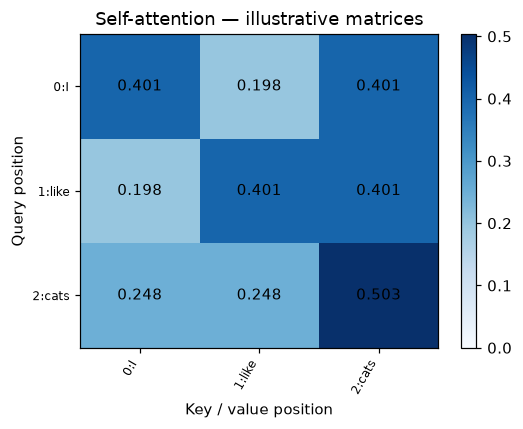

In [8]:
small_tokens=["I","like","cats"]
X=np.array([[1.,0.],[0.,1.],[1.,1.]])
WQ=WK=WV=np.eye(2)
Q,K,V=X@WQ,X@WK,X@WV
scores,A,C=scaled_dot_product_attention(Q,K,V)
for label,matrix in [("Q",Q),("K",K),("V",V),("QK^T",Q@K.T),("scaled scores",scores),("weights",A),("context",C)]:
    print("\n",label);table(matrix)
fig,ax=plt.subplots(figsize=(5,4))
im=heatmap(ax,A,small_tokens,"Self-attention — illustrative matrices")
for i in range(3):
    for j in range(3):ax.text(j,i,f"{A[i,j]:.3f}",ha="center",va="center")
plt.colorbar(im,ax=ax)
figure("self_attention_toy.png")
for i,query in enumerate(small_tokens):
    for j,key in enumerate(small_tokens):
        records.append({"record_type":"toy_self_attention","query_token":query,"key_token":key,
                        "query_position":i,"key_position":j,"score":scores[i,j],"attention":A[i,j]})

### Nhận xét — Self-attention kết hợp thông tin giữa các token

Các hàng query I/like/cats lần lượt có weights gần [0,40111; 0,19778; 0,40111], [0,19778; 0,40111; 0,40111] và [0,24826; 0,24826; 0,50349]. Mỗi hàng có tổng bằng 1; các hàng khác nhau vì query khác nhau.

Context của I≈[0,80222; 0,59889], like≈[0,59889; 0,80222], cats≈[0,75174; 0,75174]. Các vectors đầu ra khác lookup vectors ban đầu và tổng hợp thông tin từ nhiều values.

Cats ưu tiên chính nó do lựa chọn vectors tạo dot product lớn. Điều đó chưa cho thấy model học ngữ pháp. Với ba projection identity, ví dụ chủ yếu minh họa phép tính; đổi embeddings hoặc projections có thể đổi pattern. Các ma trận được ghi rõ là ví dụ bổ sung vì mục 21 chưa có dữ kiện số cụ thể.

## Chuẩn bị dữ liệu/classifier cho mục 23–24
Giữ đúng dataset/split Lab 5: 6.000 train, 2.000 validation, 2.000 test; vocabulary fit train.
Hai model train lại ở Lab 6: LSTM final state và single-head self-attention + masked mean pooling.
Cùng embedding/hidden 64, length 100, batch 128, Adam lr=0.002, dropout 0.2, 8 epochs và seed 2026.
Embedding trainable random; không pretrained, positional encoding, multi-head, residual hay Transformer block.
Padding keys bị mask; PAD query rows không tham gia pooling.

In [9]:
data,audit=load_data(ROOT)
train=data[data.split.eq("train")].reset_index(drop=True)
validation=data[data.split.eq("validation")].reset_index(drop=True)
test=data[data.split.eq("test")].reset_index(drop=True)
vocabulary=build_vocabulary(train.tokens)
(ROOT/"data"/"vocabulary.json").write_text(json.dumps(vocabulary,ensure_ascii=False,indent=2),encoding="utf-8")
table(data.groupby(["split","label"]).size().rename("count").reset_index())
print("Dataset fingerprint:",audit["subset_sha256"],"| vocabulary:",len(vocabulary))
table([{"split":name,**retention(frame.tokens.tolist(),vocabulary,100)}
       for name,frame in [("train",train),("validation",validation),("test",test)]])
for a,b in [("train","validation"),("train","test"),("validation","test")]:
    print(a,b,"shared normalized hashes:",len(set(data[data.split.eq(a)].text_hash)&set(data[data.split.eq(b)].text_hash)))
lstm=fit_sequence("LSTM",100,train,validation,vocabulary,ROOT)
attention=fit_sequence("Attention",100,train,validation,vocabulary,ROOT)
models=[lstm,attention]
table([metric_row(m,"validation") for m in models])

     split  label  count
      test      0   1000
      test      1   1000
     train      0   3000
     train      1   3000
validation      0   1000
validation      1   1000
Dataset fingerprint: 5a189f95c9a18b123a716c011a35695d5cf42cf0602e26bc3d86db238f9ff892 | vocabulary: 10000


     split  max_length  tokens_retained_percent  mean_review_retained_percent  reviews_truncated_percent  padding_percent  retained_oov_percent
     train         100                 40.34457                      56.83669                   88.28333           3.5555               4.87673
validation         100                 41.38616                      57.99689                   87.65000           3.9330               5.67469
      test         100                 41.54977                      58.11704                   87.05000           4.1320               5.99157
train validation shared normalized hashes: 0
train test shared normalized hashes: 0
validation test shared normalized hashes: 0


Loaded completed LSTM length=100; best epoch=4


Loaded completed Attention length=100; best epoch=4


record_type           model      split  seed architecture  max_length  embedding_dimension  hidden_dimension  vocabulary_size  parameters  epochs  best_epoch  training_seconds  fit_seconds  validation_loss  parameter_mib  sampled_process_rss_mib                            metric_average  accuracy  precision  recall      f1  macro_f1  tn  fp  fn  tp
 evaluation      LSTM L=100 validation  2026         LSTM         100                   64                64            10000      673345       8           4          42.17596     38.17091          0.62439        2.56861                568.01172 binary positive=1; macro_f1 also reported    0.6815    0.65606   0.763 0.70550   0.67937 600 400 237 763
 evaluation Attention L=100 validation  2026    Attention         100                   64                64            10000      652545       8           4          30.26151     26.25848          0.48783        2.48926                587.99609 binary positive=1; macro_f1 also reported    0.7790 

### Nhận xét — Điều kiện so sánh LSTM và attention

Hai model dùng cùng 6.000 train, 2.000 validation, 2.000 test reviews, vocabulary 10.000 IDs và prefix 100 tokens. Vocabulary fit trên train; từ chưa biết ở validation/test đi qua UNK. Theo bảng kiểm tra, các split không có normalized hash chung.

Length 100 chỉ giữ **40,34% tổng tokens train**, làm **88,28% reviews train** bị truncate. Vì hai model cùng chịu giới hạn này, điều kiện context được giữ giống nhau. Kết quả vẫn chưa đại diện việc xử lý toàn bộ review.

Checkpoint chọn bằng validation loss nhỏ nhất, trước khi mở test. Embedding size, batch size, learning rate và số epoch giống nhau, nhưng số parameters khác do gates và Q/K/V. Vì vậy capacity của hai model chưa hoàn toàn bằng nhau dù training settings được kiểm soát.

## 23. Experiment 3 — Attention visualization
Dùng weights từ classifier đã học IMDb sentiment trên hai câu đề bài.
Đây không phải parser hay pretrained language model; heatmap không được dùng để chứng minh hiểu grammar.
Hàng=query, cột=key/value; xem riêng cat/adopted/sleeping và báo token OOV.


 The cat that I adopted yesterday is sleeping.
OOV: []
query       key  attention
  cat        is    0.40729
  cat yesterday    0.17304
  cat  sleeping    0.13764
  query       key  attention
adopted         i    0.32326
adopted yesterday    0.21768
adopted   adopted    0.11277
   query     key  attention
sleeping       i    0.36571
sleeping      is    0.20446
sleeping adopted    0.18406

 The book that I bought yesterday was expensive.
OOV: []
query       key  attention
 book       was    0.53229
 book yesterday    0.17460
 book      that    0.14590
 query       key  attention
bought      that    0.30154
bought         i    0.22620
bought expensive    0.15627
    query  key  attention
expensive  was    0.22350
expensive that    0.18175
expensive  the    0.14216


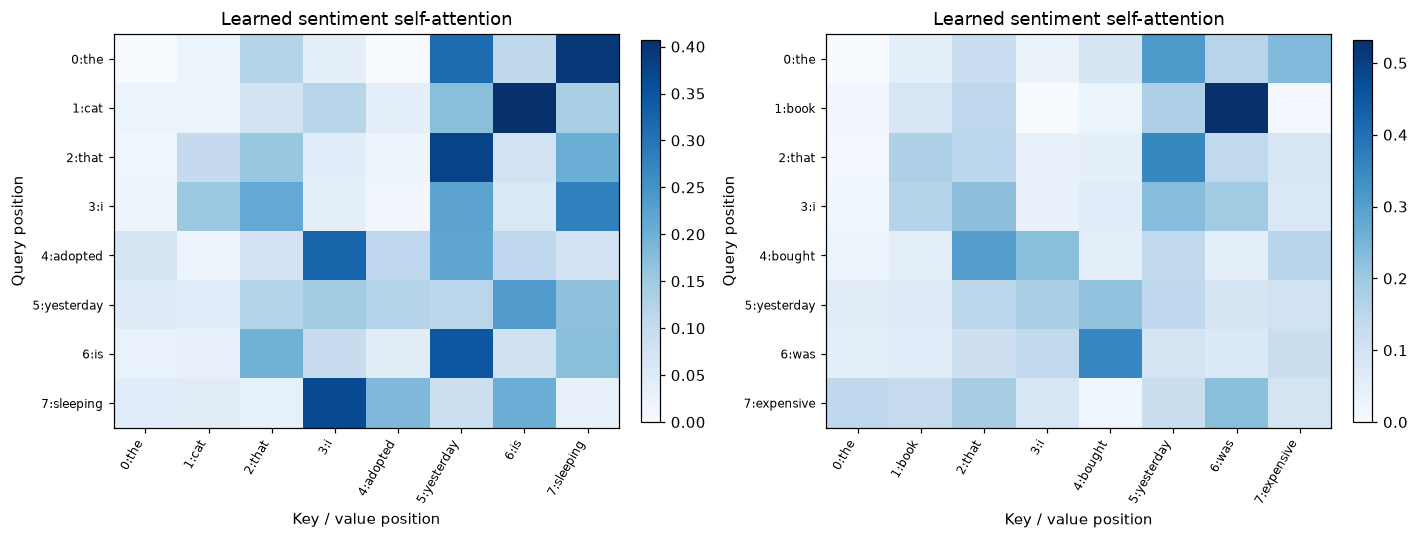

In [10]:
visual_texts=["The cat that I adopted yesterday is sleeping.",
              "The book that I bought yesterday was expensive."]
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,text in zip(axes,visual_texts):
    trace=trace_attention(attention,text,vocabulary)
    im=heatmap(ax,trace["weights"],trace["tokens"],"Learned sentiment self-attention")
    plt.colorbar(im,ax=ax,fraction=.035,pad=.04)
    print("\n",text)
    print("OOV:",[w for w in trace["tokens"] if w not in vocabulary])
    for word in (["cat","adopted","sleeping"] if "cat" in trace["tokens"] else ["book","bought","expensive"]):
        i=trace["tokens"].index(word)
        order=np.argsort(-trace["weights"][i],kind="stable")[:3]
        table([{"query":word,"key":trace["tokens"][j],"attention":trace["weights"][i,j]} for j in order])
    for i,q in enumerate(trace["tokens"]):
        for j,k in enumerate(trace["tokens"]):
            records.append({"record_type":"learned_heatmap","text":text,"query_token":q,"key_token":k,
                "query_position":i,"key_position":j,"attention":float(trace["weights"][i,j])})
figure("attention_heatmap.png")

### Nhận xét — Đọc heatmap của classifier đã học

Ở câu về con mèo, query **cat** chú ý nhiều nhất tới **is** với weight **0,4073**; **adopted** tới **i** khoảng **0,3233**; **sleeping** cũng tới **i** khoảng **0,3657**. Mỗi query tạo một cách tổng hợp context riêng, không có một phân phối chung cho mọi token.

Patterns không hoàn toàn trùng những cặp người đọc mong đợi như cat–sleeping. Model được train cho sentiment IMDb, không dùng nhãn dependency parsing. Vì vậy nên mô tả đúng phân phối quan sát thay vì diễn giải mọi ô đậm thành quan hệ ngữ pháp.

Mỗi hàng là query→key/value. Một ô hoặc cột đậm chưa cho biết nguyên nhân của nhãn sentiment. Phần application/error analysis còn đối chiếu mean received mass, signed contribution và thay đổi probability khi xóa token.

## 24. Experiment 4 — LSTM context vs Attention context
LSTM dùng state cuối của prefix. Attention tạo context cho từng query, sau đó masked mean pooling để phân loại.
Cả hai nhìn cùng prefix 100 tokens, cùng data/vocabulary/training budget; số parameters khác nhau.
Checkpoint đã khóa bằng validation loss trước khi mở test. Báo đầy đủ accuracy/precision/recall/F1/macro-F1 và cost.

record_type           model split  seed architecture  max_length  embedding_dimension  hidden_dimension  vocabulary_size  parameters  epochs  best_epoch  training_seconds  fit_seconds  validation_loss  parameter_mib  sampled_process_rss_mib                            metric_average  accuracy  precision  recall      f1  macro_f1  tn  fp  fn  tp
 evaluation      LSTM L=100  test  2026         LSTM         100                   64                64            10000      673345       8           4          42.17596     38.17091          0.62439        2.56861                568.01172 binary positive=1; macro_f1 also reported    0.6810    0.66075   0.744 0.69991   0.67973 618 382 256 744
 evaluation Attention L=100  test  2026    Attention         100                   64                64            10000      652545       8           4          30.26151     26.25848          0.48783        2.48926                587.99609 binary positive=1; macro_f1 also reported    0.7585    0.77068   0.

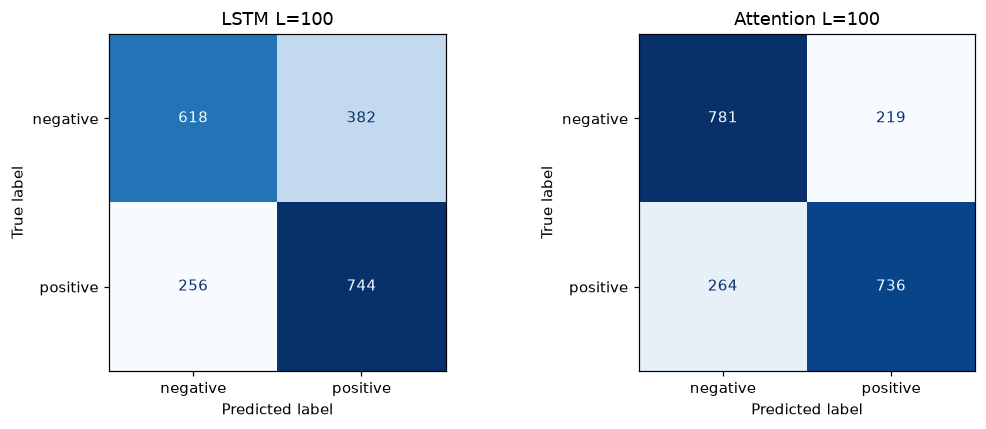

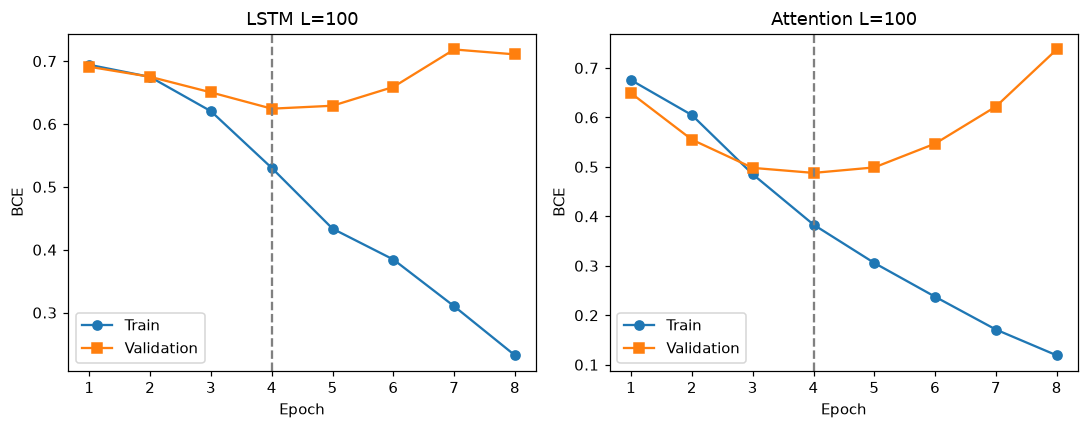

In [11]:
for item in models:
    probability=predict_sequence(item,test.text.tolist(),vocabulary)
    item["test_probability"]=probability
    item["test_pred"]=(probability>=.5).astype(int)
    item["test"]=metrics(test.label,probability)
    for split in ["validation","test"]:
        records.append(metric_row(item,split))
table([metric_row(item,"test") for item in models])
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,item in zip(axes,models):
    ConfusionMatrixDisplay(confusion_matrix(test.label,item["test_pred"],labels=[0,1]),
        display_labels=["negative","positive"]).plot(ax=ax,cmap="Blues",colorbar=False)
    ax.set_title(item["name"])
    print("\n",item["name"])
    print(classification_report(test.label,item["test_pred"],target_names=["negative","positive"],digits=4,zero_division=0))
figure("confusion_matrix.png")
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,item in zip(axes,models):
    history=pd.DataFrame(item["history"])
    ax.plot(history.epoch,history.train_loss,marker="o",label="Train")
    ax.plot(history.epoch,history.validation_loss,marker="s",label="Validation")
    ax.axvline(item["best_epoch"],ls="--",color="grey")
    ax.set_title(item["name"]);ax.set_xlabel("Epoch");ax.set_ylabel("BCE");ax.legend()
    records.extend({"record_type":"learning_curve",**row} for row in item["history"])
figure("learning_curves.png")

### Nhận xét — Kết quả phân loại và learning curves

| Chỉ số test | LSTM | Attention |
|---|---:|---:|
| Accuracy | 0,6810 | 0,7585 |
| Precision positive | 0,6607 | 0,7707 |
| Recall positive | 0,7440 | 0,7360 |
| F1 positive | 0,6999 | 0,7529 |
| False positive | 382 | 219 |
| False negative | 256 | 264 |

Attention tăng accuracy **7,75 điểm phần trăm** và tăng F1 trong lần chạy này. Cải thiện chủ yếu đi cùng giảm false positive; recall positive giảm nhẹ. Do đó không phải mọi loại lỗi đều tốt hơn.

LSTM nén prefix qua recurrent updates và lấy state ở token thật cuối. Attention tạo contexts cho nhiều query rồi masked mean pooling, cho nhiều vị trí đóng góp trực tiếp vào representation. Bản attention hiện tại vẫn có giới hạn thứ tự vì chưa nhận positional signal.

LSTM/attention có **673.345/652.545 parameters** và train-loop time khoảng **42,18/30,26 giây**. Đây là thời gian trên máy/lần chạy này, gồm validation, chưa là benchmark phổ quát.

**Learning curves:** cả hai có validation loss tốt nhất ở epoch 4. Về sau train loss tiếp tục giảm, nhưng validation loss tăng: LSTM khoảng **0,6244→0,7107**, attention **0,4878→0,7374**. Đây là dấu hiệu overfit, nên dùng checkpoint theo validation thay vì mặc định lấy epoch cuối. Một seed và một dataset chưa đủ kết luận attention luôn thắng LSTM.

### Kiểm tra giới hạn thứ tự — không thêm positional encoding
Plain self-attention là permutation-equivariant: hoán vị input làm hoán vị outputs.
Masked mean pooling tạo representation bất biến với hoán vị các tokens đã giữ.
Vì vậy classifier hiện tại không phân biệt word order trực tiếp; việc thay good bằng not good vẫn đổi multiset từ.
Bảng tổng quát của đề về sequence order cần hiểu là attention phải nhận positional signal hoặc order-aware states mới biết vị trí/thứ tự.

In [12]:
order_pairs=[("dog bites man","man bites dog"),("this movie is good","good is this movie"),
             ("I like this movie.","I do not like this movie.")]
order_rows=[]
for a,b in order_pairs:
    for item in models:
        probabilities=predict_sequence(item,[a,b],vocabulary)
        order_rows.append({"record_type":"order_probe","model":item["name"],"text_a":a,"text_b":b,
            "probability_a":float(probabilities[0]),"probability_b":float(probabilities[1]),
            "absolute_difference":float(abs(probabilities[0]-probabilities[1]))})
table(order_rows);records.extend(order_rows)
a=trace_attention(attention,"dog bites man",vocabulary)
b=trace_attention(attention,"man bites dog",vocabulary)
perm=[2,1,0]
error=float(np.max(np.abs(b["weights"]-a["weights"][np.ix_(perm,perm)])))
print("A permutation-equivariance max difference:",error)
records.append({"record_type":"permutation_equivariance","max_absolute_difference":error})

record_type           model             text_a                    text_b  probability_a  probability_b  absolute_difference
order_probe      LSTM L=100      dog bites man             man bites dog        0.74300        0.75293              0.00993
order_probe Attention L=100      dog bites man             man bites dog        0.99965        0.99965              0.00000
order_probe      LSTM L=100 this movie is good        good is this movie        0.45909        0.44056              0.01852
order_probe Attention L=100 this movie is good        good is this movie        0.97176        0.97176              0.00000
order_probe      LSTM L=100 I like this movie. I do not like this movie.        0.47819        0.23205              0.24613
order_probe Attention L=100 I like this movie. I do not like this movie.        0.19117        0.00387              0.18730
A permutation-equivariance max difference: 5.960464477539063e-08



### Nhận xét — Giới hạn thứ tự của model hiện tại

Attention cho cùng probability khoảng **0,99965** với dog bites man/man bites dog, và cùng **0,97176** với this movie is good/good is this movie. LSTM thay đổi lần lượt khoảng **0,00993** và **0,01852** giữa các thứ tự.

Kết quả phù hợp thiết kế: không có positional signal, self-attention hoán vị outputs theo input; masked mean pooling tiếp tục loại ảnh hưởng hoán vị. Classifier attention vì thế chưa trực tiếp phân biệt word order trong các tokens được giữ.

Thêm not làm thay đổi multiset từ nên attention vẫn có thể đổi probability. Điều đó chưa chứng minh hiểu scope phủ định. Tương tự, output LSTM đổi khi hoán vị chỉ chứng minh độ nhạy với order, chưa chứng minh hiểu vai trò chủ thể–đối tượng.

## 25. Experiment 5 — Sequence length và computational cost
T=10/100/500/1000; bổ sung T=10.000 để tính lý thuyết. Một full self-attention matrix chứa T² phần tử.
Benchmark NumPy float64, d_k=d_v=32, median ba lần sau warm-up, chỉ thực đo đến T=1000.
Không cấp phát ma trận 10.000². MiB lý thuyết bên dưới chỉ cho một A hoặc scores+A,
chưa gồm batch, gradients, Q/K/V hoặc optimizer. Single-query attention lên T keys chỉ cần T weights.

   record_type  sequence_length  matrix_elements  single_query_elements  A_float32_MiB  scores_plus_A_float32_MiB  A_float64_MiB  median_numpy_seconds
attention_cost               10              100                     10        0.00038                    0.00076        0.00076               0.00007
attention_cost              100            10000                    100        0.03815                    0.07629        0.07629               0.00048
attention_cost              500           250000                    500        0.95367                    1.90735        1.90735               0.01506
attention_cost             1000          1000000                   1000        3.81470                    7.62939        7.62939               0.05394
attention_cost            10000        100000000                  10000      381.46973                  762.93945      762.93945                   NaN


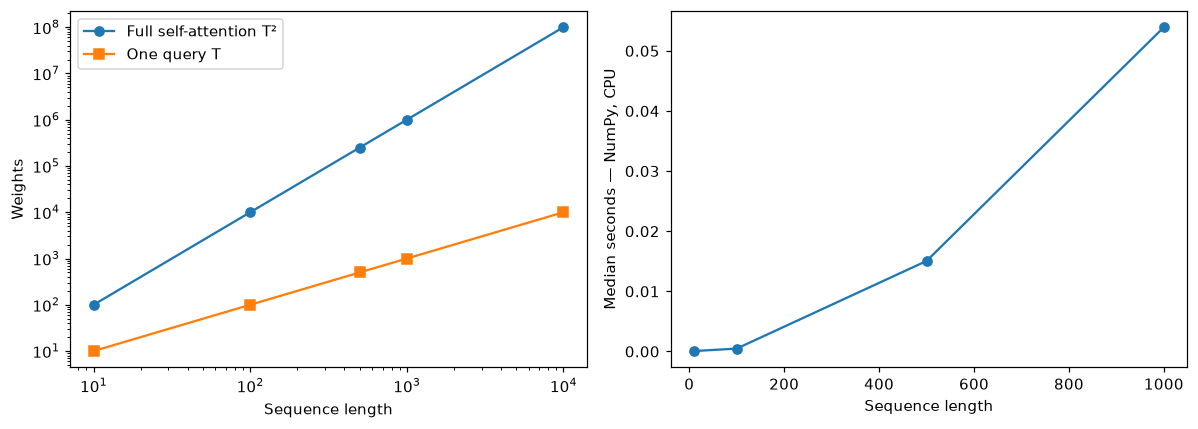

In [13]:
rng=np.random.default_rng(SEED)
cost_rows=[]
for length in [10,100,500,1000,10000]:
    count=length*length
    seconds=np.nan
    if length<=1000:
        Q=rng.normal(size=(length,32));K=rng.normal(size=(length,32));V=rng.normal(size=(length,32))
        scaled_dot_product_attention(Q,K,V)
        timings=[]
        for _ in range(3):
            start=time.perf_counter();scaled_dot_product_attention(Q,K,V)
            timings.append(time.perf_counter()-start)
        seconds=float(np.median(timings))
    cost_rows.append({"record_type":"attention_cost","sequence_length":length,
        "matrix_elements":count,"single_query_elements":length,
        "A_float32_MiB":count*4/1024**2,"scores_plus_A_float32_MiB":count*8/1024**2,
        "A_float64_MiB":count*8/1024**2,"median_numpy_seconds":seconds})
table(cost_rows);records.extend(cost_rows)
cost=pd.DataFrame(cost_rows)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].loglog(cost.sequence_length,cost.matrix_elements,marker="o",label="Full self-attention T²")
axes[0].loglog(cost.sequence_length,cost.single_query_elements,marker="s",label="One query T")
axes[0].set_ylabel("Weights");axes[0].legend()
measured=cost.dropna(subset=["median_numpy_seconds"])
axes[1].plot(measured.sequence_length,measured.median_numpy_seconds,marker="o")
axes[1].set_ylabel("Median seconds — NumPy, CPU")
for ax in axes:ax.set_xlabel("Sequence length")
figure("attention_cost.png")

### Nhận xét — Computational cost khi tăng length

| Length | Phần tử full matrix | Memory một A float32 |
|---|---:|---:|
| 10 | 100 | 0,00038 MiB |
| 100 | 10.000 | 0,03815 MiB |
| 500 | 250.000 | 0,95367 MiB |
| 1.000 | 1.000.000 | 3,81470 MiB |
| 10.000 | 100.000.000 | 381,46973 MiB |

Length tăng gấp đôi làm phần tử tăng bốn lần. Từ 1.000→10.000 tokens, attention matrix tăng **100 lần**. Memory trên mới tính một A; scores, Q/K/V, gradients, batch hoặc nhiều heads cần thêm tài nguyên.

Benchmark thực đo tới 1.000 tokens; 10.000 chỉ tính kích thước lý thuyết. Runtime còn chịu ảnh hưởng BLAS, bộ nhớ và warm-up, nên vài điểm đo chưa xác định chính xác một hệ số tăng tốc.

Full self-attention có T queries và T keys nên cần T² weights. Attention chỉ có một query lên T keys cần T weights. Khi diễn giải cost cần nêu cả số query lẫn số key.

## 26. Application — Context-aware sentiment
Thử ba câu đúng theo đề, có expected label tham khảo theo nội dung rõ của câu.
Nếu cả ba đều đúng hoặc đều sai, bổ sung một review test để có ít nhất một trường hợp đúng và một sai.
Heatmap là query→key distribution. Mean received mass beta_j là trung bình weights từ các query thật tới key j.
Ở eval, linear head trên masked-mean context có logit=b+sum_j beta_j(wᵀv_j).
Signed value contribution vì vậy khác attention weight và không được gọi là causal importance.


APPLICATION 1 I like this movie.
Prediction: negative P: 0.19117 expected: 1
 position token  received_mass  signed_value_contribution
        0     i        0.34543                    3.41515
        1  like        0.27320                   -0.42183
        3 movie        0.20086                   -0.48015
        2  this        0.18051                   -4.01868


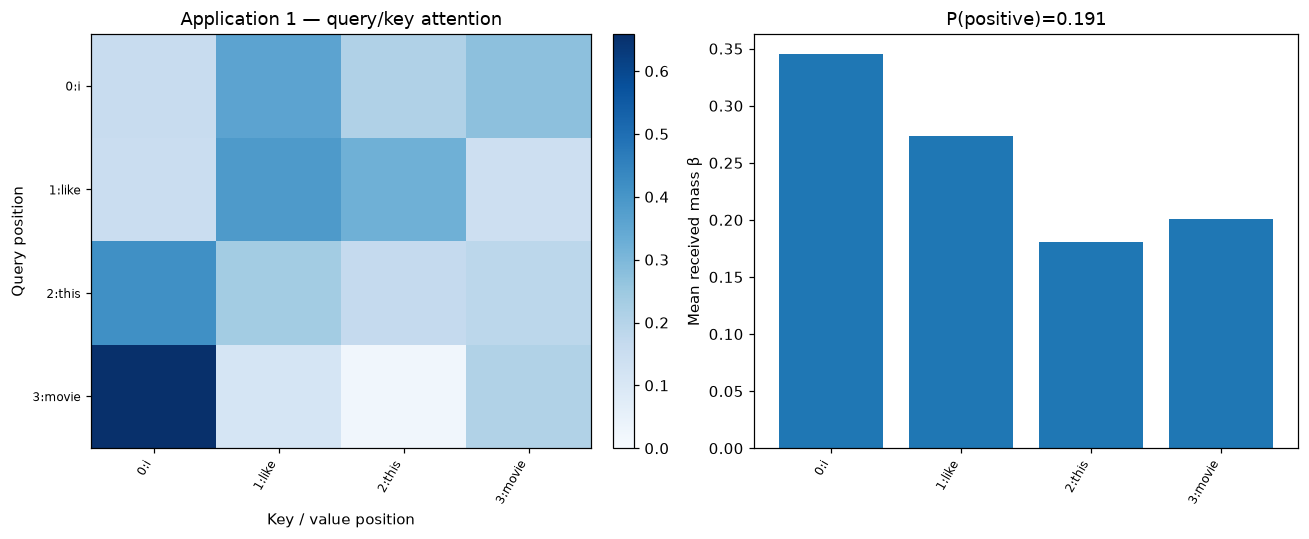



APPLICATION 2 I do not like this movie.
Prediction: negative P: 0.00387 expected: 0
 position token  received_mass  signed_value_contribution
        2   not        0.31793                   -2.35351
        0     i        0.19609                    1.93862
        1    do        0.14279                   -2.66974
        5 movie        0.12861                   -0.30745
        3  like        0.12333                   -0.19043


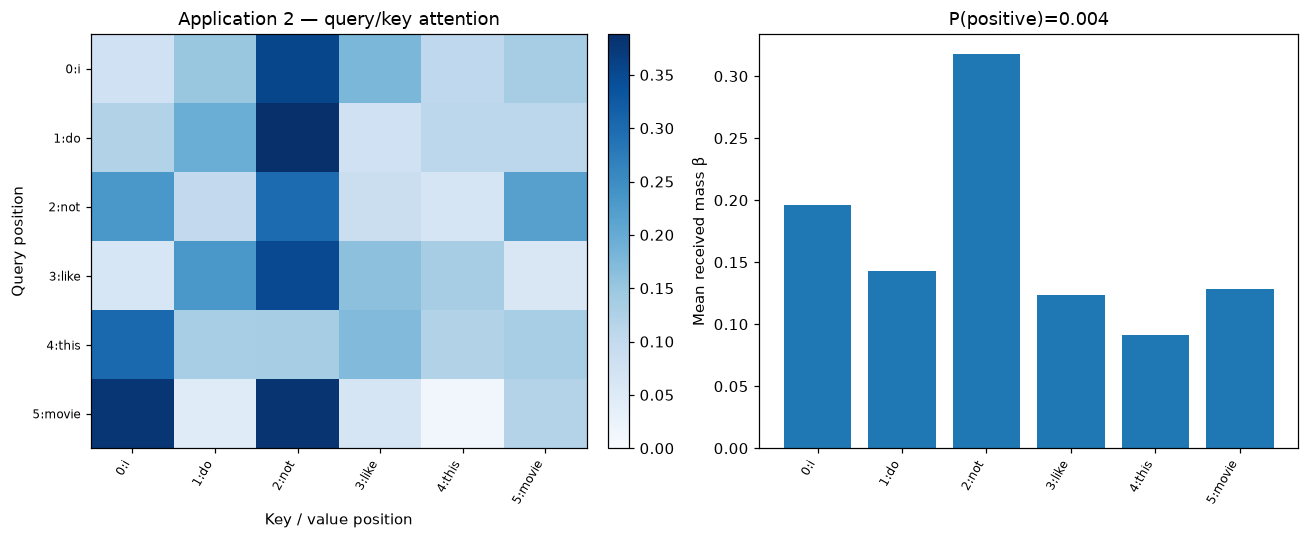



APPLICATION 3 I thought this movie would be bad, but it was actually excellent.
Prediction: negative P: 0.03063 expected: 1
 position     token  received_mass  signed_value_contribution
        6       bad        0.19612                   -4.88553
       11 excellent        0.18187                    3.06755
        0         i        0.13853                    1.36962
        5        be        0.08507                   -1.50924
        1   thought        0.06883                    0.05536


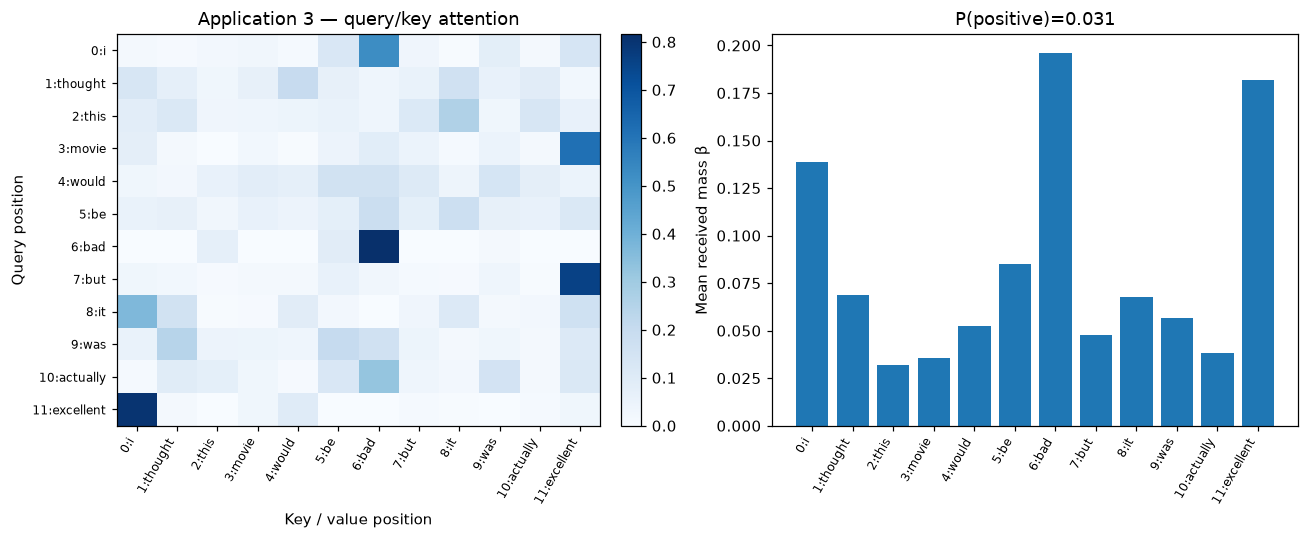


record_type  case     kind                                                              text   source  true_label  prediction  correct  probability  decomposition_error  original_length  retained_length
application     1 positive                                                I like this movie. given W6           1           0    False      0.19117                  0.0                4                4
application     2 negation                                         I do not like this movie. given W6           0           0     True      0.00387                  0.0                6                6
application     3 contrast I thought this movie would be bad, but it was actually excellent. given W6           1           0    False      0.03063                  0.0               12               12


In [14]:
application_inputs=[
 {"kind":"positive","text":"I like this movie.","expected_label":1,"source":"given W6"},
 {"kind":"negation","text":"I do not like this movie.","expected_label":0,"source":"given W6"},
 {"kind":"contrast","text":"I thought this movie would be bad, but it was actually excellent.","expected_label":1,"source":"given W6"}
]
given_prob=predict_sequence(attention,[row["text"] for row in application_inputs],vocabulary)
given_correct=[int(prob>=.5)==row["expected_label"] for row,prob in zip(application_inputs,given_prob)]
for wanted in [True,False]:
    if wanted in given_correct:
        continue
    candidates=np.flatnonzero((attention["test_pred"]==test.label.to_numpy())==wanted)
    i=min(candidates,key=lambda i:(test.iloc[i].length,int(i)))
    application_inputs.append({"kind":"test_correct_reference" if wanted else "test_error_reference",
        "text":test.iloc[i].text,"expected_label":int(test.iloc[i].label),"source":test.iloc[i].id})
application_rows=[]
for number,row in enumerate(application_inputs,1):
    trace=trace_attention(attention,row["text"],vocabulary)
    top=token_table(trace).sort_values("received_mass",ascending=False).head(5)
    predicted=int(trace["probability"]>=.5)
    info={"record_type":"application","case":number,"kind":row["kind"],"text":row["text"],"source":row["source"],
        "true_label":row["expected_label"],"prediction":predicted,"correct":predicted==row["expected_label"],
        "probability":trace["probability"],"decomposition_error":trace["decomposition_error"],
        "original_length":len(tokenize(row["text"])),"retained_length":len(trace["tokens"])}
    application_rows.append(info);records.append(info)
    print("\nAPPLICATION",number,row["text"])
    print("Prediction:",["negative","positive"][predicted],"P:",round(trace["probability"],5),"expected:",row["expected_label"])
    table(top)
    fig,axes=plt.subplots(1,2,figsize=(12,5))
    im=heatmap(axes[0],trace["weights"],trace["tokens"],f"Application {number} — query/key attention")
    plt.colorbar(im,ax=axes[0],fraction=.04,pad=.04)
    axes[1].bar(np.arange(len(trace["tokens"])),trace["mass"])
    ticks=list(range(0,len(trace["tokens"]),max(1,int(np.ceil(len(trace["tokens"])/20)))))
    axes[1].set_xticks(ticks,[f"{i}:{trace['tokens'][i]}" for i in ticks],rotation=60,ha="right",fontsize=8)
    axes[1].set_ylabel("Mean received mass β");axes[1].set_title(f"P(positive)={trace['probability']:.3f}")
    figure(f"application_{number}.png")
    for i,token in enumerate(trace["tokens"]):
        records.append({"record_type":"application_token","case":number,"position":i,"token":token,
            "attention":float(trace["mass"][i]),"signed_contribution":float(trace["contributions"][i])})
table(application_rows)

### Nhận xét — Ba câu application

**I like this movie — sai:** P(positive)=**0,1912**, dự đoán negative. I có mean received mass lớn nhất khoảng 0,3454, nhưng đóng góp dương **+3,4152** không bù được contribution của this **−4,0187** và các thành phần khác. Token có mass lớn nhất chưa đủ cho biết hướng prediction.

**I do not like this movie — đúng:** P=**0,00387**, dự đoán negative. Not nhận mass khoảng 0,3179, contribution **−2,3535**; do và this cũng có contributions âm. Kết quả phù hợp việc thêm tín hiệu phủ định, nhưng chưa chứng minh model hiểu đầy đủ phạm vi phủ định.

**Câu contrast — sai:** P=**0,0306**, dự đoán negative dù vế sau khen phim. Bad có mass khoảng 0,1961 và contribution **−4,8855**; excellent có mass khoảng 0,1819 và contribution **+3,0676**. Tín hiệu khen đã có tác động dương nhưng tổng logit vẫn âm.

Ba câu đều dưới 100 tokens nên lỗi không do mất phần đuôi. Có thể xem xét learned lexical weighting, khác biệt giữa câu ngắn và review IMDb, cùng giới hạn chưa có positional signal. Các quan sát mô tả behavior, chưa chứng minh một ô attention là nguyên nhân nhân quả duy nhất.

## 27. Error analysis — ba đúng và ba sai
Dùng attention model; chọn ít nhất ba correct và ba incorrect, bao phủ hai nhãn khi có.
Báo full review, phần nhìn thấy/bị bỏ, OOV và top attention mass/contribution.
Cue list là gợi ý AI để đọc review, không phải nhãn gold về token importance hay prediction cá nhân.
Xóa token attention lớn nhất và token |signed contribution| lớn nhất để đối chiếu model behavior;
xóa token có thể thay toàn bộ attention và kéo thêm token mới vào prefix, nên không là can thiệp nhân quả hoàn hảo.


CASE 1 | true 0 pred 0 P 0.0
FULL: This is quite possibly the worst sequel ever made. The script is unfunny and the acting stinks. The exact opposite of the original.
RETAINED: this is quite possibly the worst sequel ever made the script is unfunny and the acting stinks the exact opposite of the original
REMOVED: [none]
 position    token  received_mass  signed_value_contribution
        5    worst        0.32477                   -7.58794
       10   script        0.20731                   -5.13187
       15   acting        0.05042                   -0.75887
       13      and        0.04704                    0.81581
        7     ever        0.04056                    0.30975
        0     this        0.03885                   -0.86483
       20       of        0.02847                    0.28104
       19 opposite        0.02817                   -0.31087

CASE 2 | true 1 pred 1 P 0.9664
FULL: Just love the interplay between two great characters of stage & screen - Veidt & Barrymor

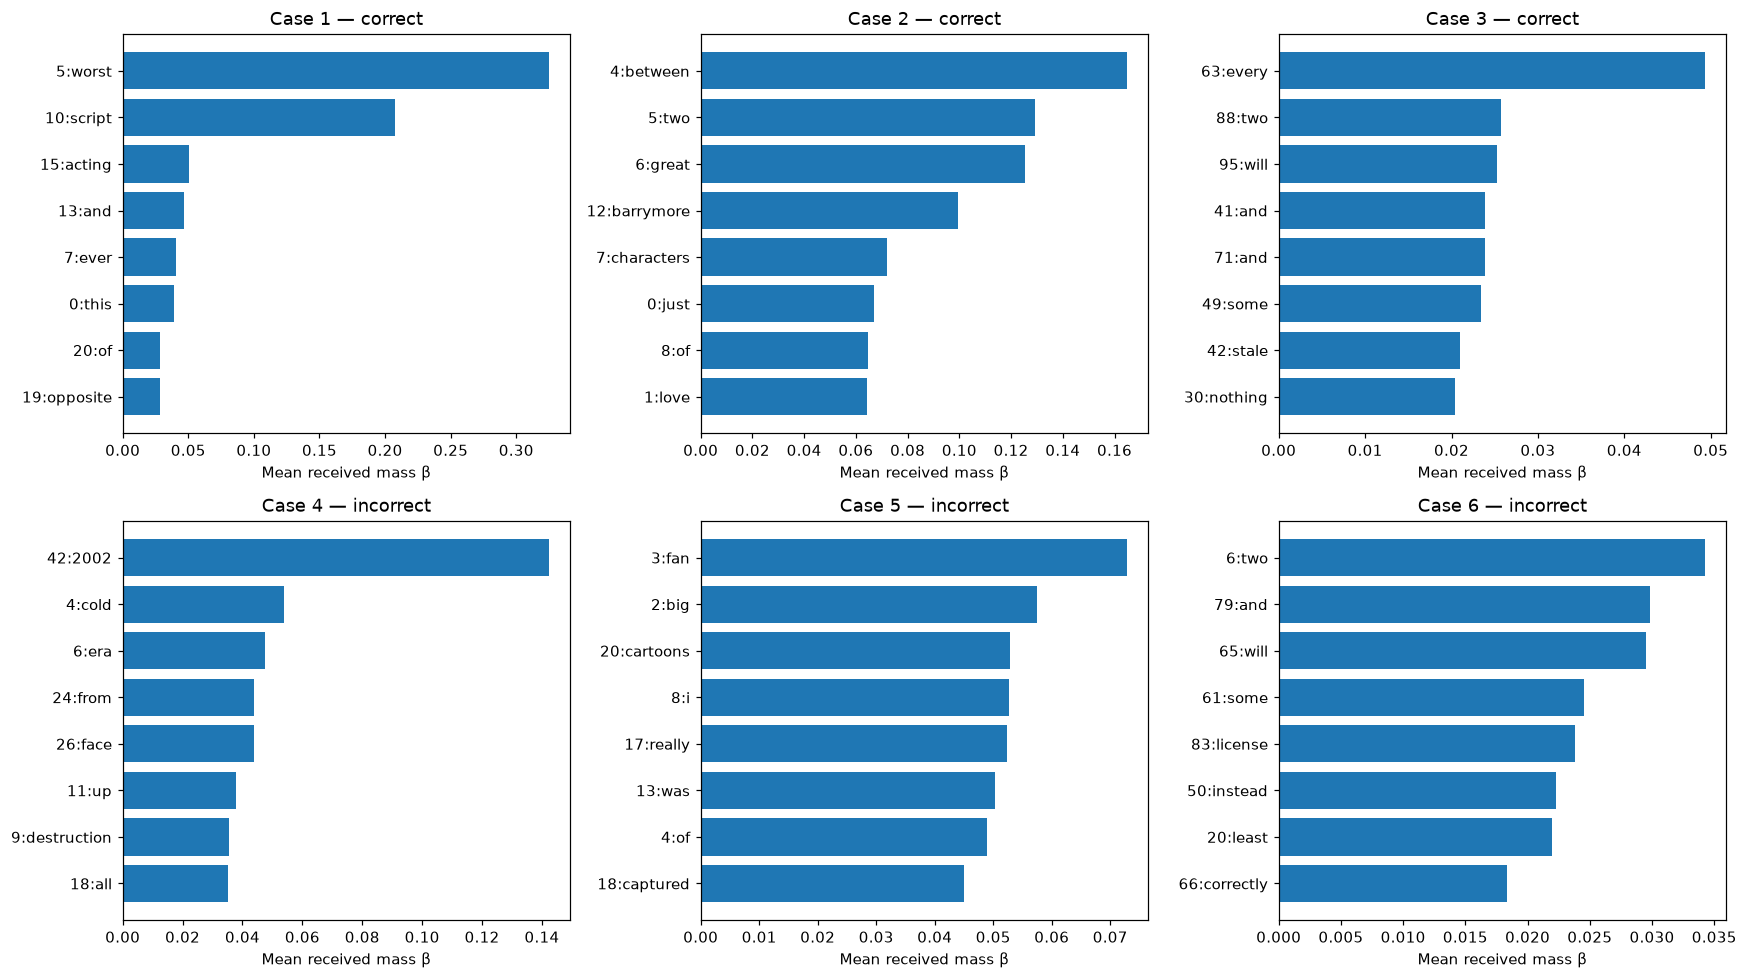

 case                           id  true_label  prediction  correct  probability  lstm_prediction                                                         category  original_length  retained_length  truncated  oov_fraction top_mass_token top_signed_token  p_drop_top_mass  p_drop_top_signed  decomposition_error
    1  aclImdb/test/neg/3254_1.txt           0           0     True      0.00000                0                                                  Tín hiệu chê rõ               23               23      False       0.00000          worst            worst          0.00014            0.00014                  0.0
    2  aclImdb/test/pos/9148_9.txt           1           1     True      0.96643                1                            Tín hiệu khen; mass khác contribution               13               13      False       0.15385        between            great          0.99312            0.81801                  0.0
    3  aclImdb/test/neg/8440_1.txt           0           0     True

12552

In [15]:
cue_set={"not","no","never","good","bad","excellent","terrible","love","loved","boring","worst","best",
         "but","however","great","enjoyed","waste","awful","wonderful","fun"}
error_rows=[]
fig,axes=plt.subplots(2,3,figsize=(16,9))
for number,i in enumerate(select_examples(attention,test),1):
    row=test.iloc[i];words=tokenize(row.text)
    trace=trace_attention(attention,row.text,vocabulary)
    visible=trace["tokens"];removed=words[attention["max_length"]:]
    top_mass=int(np.argmax(trace["mass"]));top_signed=int(np.argmax(np.abs(trace["contributions"])))
    p_drop_mass=occlude_token(attention,row.text,vocabulary,top_mass)
    p_drop_signed=occlude_token(attention,row.text,vocabulary,top_signed)
    top_indices=np.argsort(-trace["mass"],kind="stable")[:8]
    cues=[w for w in visible if w in cue_set]
    correct=int(trace["probability"]>=.5)==int(row.label)
    category=("Phù hợp nhãn" if correct else
              "Truncation cần kiểm tra" if removed else
              "Negation/contrast cần kiểm tra" if any(w in visible for w in ["not","but","however"]) else
              "Ambiguous wording / rare word — giả thuyết")
    oov=sum(w not in vocabulary for w in visible)/max(len(visible),1)
    category=case_categories.get(row.id,category)
    analysis=case_discussions.get(row.id,"")
    info={"record_type":"error_analysis","case":number,"id":row.id,"text":row.text,
        "true_label":int(row.label),"prediction":int(trace["probability"]>=.5),"correct":correct,
        "probability":trace["probability"],"lstm_prediction":int(lstm["test_pred"][i]),"category":category,
        "original_length":len(words),"retained_length":len(visible),"truncated":bool(removed),
        "oov_fraction":oov,"top_mass_token":visible[top_mass],"top_signed_token":visible[top_signed],
        "p_drop_top_mass":p_drop_mass,"p_drop_top_signed":p_drop_signed,
        "decomposition_error":trace["decomposition_error"],
        "retained_text":" ".join(visible),"removed_text":" ".join(removed),"analysis":analysis}
    error_rows.append(info);records.append(info)
    print("\nCASE",number,"| true",row.label,"pred",info["prediction"],"P",round(info["probability"],4))
    print("FULL:",row.text);print("RETAINED:",info["retained_text"]);print("REMOVED:",info["removed_text"] or "[none]")
    table(token_table(trace).iloc[top_indices])
    ax=axes.flat[number-1]
    ax.barh([f"{j}:{visible[j]}" for j in top_indices][::-1],trace["mass"][top_indices][::-1])
    ax.set_title(f"Case {number} — {'correct' if correct else 'incorrect'}")
    ax.set_xlabel("Mean received mass β")
    for j in range(len(visible)):
        records.append({"record_type":"error_attention_token","case":number,"position":j,"token":visible[j],
                       "attention":float(trace["mass"][j]),"signed_contribution":float(trace["contributions"][j])})
figure("error_attention.png")
table(pd.DataFrame(error_rows).drop(columns=["record_type","text","retained_text","removed_text","analysis"]))
(ROOT/"error_analysis.md").write_text("\n\n".join(error_report_sections),encoding="utf-8")

### Nhận xét — Tổng hợp sáu trường hợp phân tích lỗi

Ba dự đoán đúng gồm review chê rõ, review khen rõ và một review dài hơn 100 tokens. Ba dự đoán sai gồm nội dung khó diễn giải/OOV cao, lời khen về phim hoạt hình và review chê độ chính xác lịch sử. Các ví dụ được chọn để đọc hành vi, không đại diện tỷ lệ nguyên nhân trên toàn test.

Cần phân biệt **mean received mass**, **signed value contribution** và **kết quả khi xóa token**. Mass lớn cho biết value được trộn với hệ số lớn; contribution còn phụ thuộc value và trọng số linear head. Xóa token có thể thay toàn bộ attention. Ba đại lượng vì thế cung cấp các góc nhìn khác nhau.

Between nhận mass cao nhất trong một review positive nhưng great có contribution dương lớn hơn. Ở một lỗi khác, 2002 có mass cao nhưng contribution âm; xóa nó làm dự đoán positive sai mạnh hơn. Các trường hợp này không hỗ trợ kết luận đơn giản rằng chú ý vào từ không hợp kỳ vọng con người là nguyên nhân gây sai. Cần đọc từng review cùng số liệu cụ thể.

#### Trường hợp 1 — Dự đoán đúng

**Review ID:** aclImdb/test/neg/3254_1.txt  
**Nhãn thật:** negative; **dự đoán:** negative; **P(positive):** 0.00000.  
**Nhóm quan sát/giả thuyết:** Tín hiệu chê rõ.

**Văn bản để đối chiếu:**

> This is quite possibly the worst sequel ever made. The script is unfunny and the acting stinks. The exact opposite of the original.

**Phần input model nhận:** 23/23 tokens; tỷ lệ OOV trong phần giữ lại là 0.00%.

Review không bị truncate, nên không giải thích bằng việc mất phần đuôi.

**Diễn giải kết quả:** Worst sequel, unfunny và acting stinks thể hiện lời chê. Worst nhận mass cao nhất và contribution âm lớn. Xóa worst vẫn cho P rất thấp vì review còn nhiều tín hiệu chê. Trường hợp đúng này phù hợp lexical evidence, chưa chứng minh reasoning.

**Đối chiếu diagnostic:** xóa token mass lớn nhất (worst) cho P=0.00014;
xóa token có |signed contribution| lớn nhất (worst) cho P=0.00014.
Phép xóa có thể làm thay đổi attention của các token còn lại; kết quả hỗ trợ mô tả độ nhạy, không phải chứng minh nhân quả hoàn chỉnh.

#### Trường hợp 2 — Dự đoán đúng

**Review ID:** aclImdb/test/pos/9148_9.txt  
**Nhãn thật:** positive; **dự đoán:** positive; **P(positive):** 0.96643.  
**Nhóm quan sát/giả thuyết:** Tín hiệu khen; mass khác contribution.

**Văn bản để đối chiếu:**

> Just love the interplay between two great characters of stage & screen - Veidt & Barrymore

**Phần input model nhận:** 13/13 tokens; tỷ lệ OOV trong phần giữ lại là 15.38%.

Review không bị truncate, nên không giải thích bằng việc mất phần đuôi.

**Diễn giải kết quả:** Love và great thể hiện lời khen. Between có received mass lớn nhất 0,1647 nhưng contribution=-0,2998; great có mass thấp hơn 0,1255 nhưng contribution=+2,0796. Xóa great giảm P từ 0,9664 xuống 0,8180, vẫn positive; xóa between lại nâng P lên 0,9931. Không thể suy importance chỉ từ attention mass.

**Đối chiếu diagnostic:** xóa token mass lớn nhất (between) cho P=0.99312;
xóa token có |signed contribution| lớn nhất (great) cho P=0.81801.
Phép xóa có thể làm thay đổi attention của các token còn lại; kết quả hỗ trợ mô tả độ nhạy, không phải chứng minh nhân quả hoàn chỉnh.

#### Trường hợp 3 — Dự đoán đúng

**Review ID:** aclImdb/test/neg/8440_1.txt  
**Nhãn thật:** negative; **dự đoán:** negative; **P(positive):** 0.17736.  
**Nhóm quan sát/giả thuyết:** Đúng dù mất một token cuối.

**Văn bản để đối chiếu:**

> this was absolutely the most tragic pile of cinema to which i have ever born witness. not only was the name a complete misnomer--since the film has next to nothing to do with piranhas--but the acting is as hollow and stale as the attempt to actually make some kind of plot. when you watch this film you cannot help but spend every waking second questioning when you've had enough and it's time to turn it off. unfortunately i waited until the end in my case. that's two hours of my life that i will never be able to reclaim.

**Phần input model nhận:** 100/101 tokens; tỷ lệ OOV trong phần giữ lại là 2.00%.

Phần bị bỏ: **reclaim**. Cần xem mức mất thông tin thực tế trước khi quy lỗi cho truncation.

**Diễn giải kết quả:** Review có tragic pile, hollow and stale và unfortunately trong retained text. Chỉ mất reclaim, nên chưa có bằng chứng truncation gây mất quyết định sentiment. Top received mass ở every không phải một sentiment word rõ; model vẫn đúng. Không đòi mọi token mass cao đều trùng cue con người.

**Đối chiếu diagnostic:** xóa token mass lớn nhất (every) cho P=0.25509;
xóa token có |signed contribution| lớn nhất (every) cho P=0.25509.
Phép xóa có thể làm thay đổi attention của các token còn lại; kết quả hỗ trợ mô tả độ nhạy, không phải chứng minh nhân quả hoàn chỉnh.

#### Trường hợp 4 — Dự đoán sai

**Review ID:** aclImdb/test/neg/7086_4.txt  
**Nhãn thật:** negative; **dự đoán:** positive; **P(positive):** 0.59168.  
**Nhóm quan sát/giả thuyết:** Ambiguous wording / OOV — hypothesis.

**Văn bản để đối chiếu:**

> An intelligent summation of Cold War era mutually assured destruction policy, up until the conclusion: it's a gasser! All Russians and Chinese are obliterated from the face of the Earth! Saw this one at the 27th Annual CWRU Science Fiction Marathon, January 2002.

**Phần input model nhận:** 43/43 tokens; tỷ lệ OOV trong phần giữ lại là 20.93%.

Review không bị truncate, nên không giải thích bằng việc mất phần đuôi.

**Diễn giải kết quả:** Review không bị truncate, OOV khoảng 20,93%; intelligent và phần kết khó diễn giải làm sentiment không rõ chỉ bằng từ khóa. 2002 có mass cao nhất nhưng signed contribution=-1,8722. Xóa 2002 làm P tăng từ 0,5917 lên 0,9277, tức dự đoán sai còn nghiêng positive hơn. Không thể nói nhìn vào năm là nguyên nhân gây sai; token này đang kéo logit về negative trong phép phân rã.

**Đối chiếu diagnostic:** xóa token mass lớn nhất (2002) cho P=0.92771;
xóa token có |signed contribution| lớn nhất (2002) cho P=0.92771.
Phép xóa có thể làm thay đổi attention của các token còn lại; kết quả hỗ trợ mô tả độ nhạy, không phải chứng minh nhân quả hoàn chỉnh.

#### Trường hợp 5 — Dự đoán sai

**Review ID:** aclImdb/test/pos/4922_10.txt  
**Nhãn thật:** positive; **dự đoán:** negative; **P(positive):** 0.41558.  
**Nhóm quan sát/giả thuyết:** Domain-specific wording / learned lexical weighting — hypothesis.

**Văn bản để đối chiếu:**

> As a big fan of Tiny Toon Adventures, I loved this movie!!! It was so funny!!! It really captured how cartoons spent their summers.

**Phần input model nhận:** 24/24 tokens; tỷ lệ OOV trong phần giữ lại là 8.33%.

Review không bị truncate, nên không giải thích bằng việc mất phần đuôi.

**Diễn giải kết quả:** Nội dung khen rõ: loved this movie, so funny. Fan có mass cao nhất; this có |contribution| lớn nhất. Xóa fan hoặc this đổi P từ 0,4156 lên 0,5467 hoặc 0,5822, làm prediction chuyển positive. Đây là bằng chứng model nhạy với lexical/context weighting trên review hoạt hình, chưa chứng minh nguyên nhân duy nhất hoặc attention mass tương đương causal importance.

**Đối chiếu diagnostic:** xóa token mass lớn nhất (fan) cho P=0.54673;
xóa token có |signed contribution| lớn nhất (this) cho P=0.58217.
Phép xóa có thể làm thay đổi attention của các token còn lại; kết quả hỗ trợ mô tả độ nhạy, không phải chứng minh nhân quả hoàn chỉnh.

#### Trường hợp 6 — Dự đoán sai

**Review ID:** aclImdb/test/neg/4583_4.txt  
**Nhãn thật:** negative; **dự đoán:** positive; **P(positive):** 0.65660.  
**Nhóm quan sát/giả thuyết:** Contrast / conditional context — hypothesis.

**Văn bản để đối chiếu:**

> But like the Disney film of two generations ago, this film fails as well in the accuracy department. But at least Disney used a Skye Terrier.<br /><br />Is the true story to mundane for movie producers? I don't think so. There is ample documentation to accurately portray they true story instead of the fictionalized accounts we have had to suffer through. <br /><br />Some day, a movie will correctly portray Bobby's owner, John Gray, as the Edinburgh Policeman that he was, and correctly portray Bobby's license a being paid for by the Lord Provost. When that happens, I'll be at the theaters.

**Phần input model nhận:** 100/100 tokens; tỷ lệ OOV trong phần giữ lại là 8.00%.

Review không bị truncate, nên không giải thích bằng việc mất phần đuôi.

**Diễn giải kết quả:** Review chê độ chính xác lịch sử và các fictionalized accounts, rồi nói sẽ xem một phim đúng lịch sử trong tương lai. Đủ 100 tokens, không bị truncate. Mass cao nhất ở two, contribution lớn nhất ở and; xóa riêng từng token làm P giảm nhưng vẫn positive (0,6001/0,5809). Mô hình có thể chưa phân biệt lời chê phim hiện tại với mong muốn tương lai; kiến trúc không có positional signal là một giới hạn, nhưng chưa có can thiệp đủ để xác định nguyên nhân duy nhất.

**Đối chiếu diagnostic:** xóa token mass lớn nhất (two) cho P=0.60005;
xóa token có |signed contribution| lớn nhất (and) cho P=0.58092.
Phép xóa có thể làm thay đổi attention của các token còn lại; kết quả hỗ trợ mô tả độ nhạy, không phải chứng minh nhân quả hoàn chỉnh.



## 29. Attention không miễn phí
T=1000: 1.000.000 phần tử; T=10.000: 100.000.000 phần tử.
Một A float32 lần lượt khoảng 3,81 và 381,47 MiB, chưa gồm scores/gradients/batch/heads.
Không suy ra Attention luôn thay thế RNN hoặc luôn tốt hơn trên mọi task.

In [16]:
properties=[
 {"Property":"Order trực tiếp","LSTM":"Có qua recurrence","Attention hiện tại":"Không, chưa có positional signal"},
 {"Property":"Representation","LSTM":"Final recurrent state","Attention hiện tại":"Mean của weighted combinations"},
 {"Property":"Direct token interaction","LSTM":"Qua nhiều timestep","Attention hiện tại":"Có QKᵀ toàn chuỗi"},
 {"Property":"Parallel query computation","LSTM":"Hạn chế theo timestep","Attention hiện tại":"Có"},
 {"Property":"Cost theo T, dimensions cố định","LSTM":"Gần tuyến tính","Attention hiện tại":"T² full attention"},
 {"Property":"Long-range interaction","LSTM":"Truyền qua states","Attention hiện tại":"Trực tiếp, vẫn có giới hạn học/position/cost"}]
table(properties)

                       Property                  LSTM                           Attention hiện tại
                Order trực tiếp     Có qua recurrence             Không, chưa có positional signal
                 Representation Final recurrent state               Mean của weighted combinations
       Direct token interaction    Qua nhiều timestep                            Có QKᵀ toàn chuỗi
     Parallel query computation Hạn chế theo timestep                                           Có
Cost theo T, dimensions cố định        Gần tuyến tính                            T² full attention
         Long-range interaction     Truyền qua states Trực tiếp, vẫn có giới hạn học/position/cost



### Nhận xét tổng hợp — Lợi ích và giới hạn của attention

Attention cho tương tác trực tiếp giữa các vị trí còn trong input và tính nhiều queries bằng phép toán ma trận. Nó giảm yêu cầu truyền mọi thông tin xa qua một chuỗi recurrent dài và tạo nhiều context vectors trước pooling.

Full attention đồng thời tạo ma trận T×T nên cost tăng nhanh với chuỗi dài. Nó cũng không tự biết vị trí: cấu hình của bài này cần positional signal ở bước sau để biểu diễn order trực tiếp. Thông tin đã bị truncate vẫn không được attention khôi phục.

F1 tốt hơn LSTM là kết quả của cấu hình đã chạy. Những lỗi application, sự khác nhau giữa top attention mass và top signed contribution, cùng hiện tượng overfit cho thấy attention chưa đồng nghĩa hiểu ngôn ngữ hay reasoning. Các hướng kiểm tra tiếp theo gồm nhiều seed, xử lý độ dài và positional encoding/Transformer; chúng chưa được triển khai trong Lab 6.

## 30. AI assistance statement
Tool: Codex. Purpose: implementation, NumPy/PyTorch API, debugging, training loop, visualization và documentation.
Generated: code, notebook, output thực nghiệm và các đoạn tham khảo.
Modified: sinh viên tự ghi phần đã sửa. Verified: output đã chạy; người học cần tự kiểm tra suy luận.
Theo W6, calculation, prediction cá nhân, Q/K/V explanation, attention interpretation, error analysis,
reflection và individual check cần người học tự thực hiện. 



## 32–34. Deliverables, rubric và peer assessment
README.md, calculations.md, prediction.md, attention_numpy.py, self_attention.ipynb, results.csv,
data/attention_heatmap.png, data/confusion_matrix.png, error_analysis.md, reflection.md.
Thêm preprocessing.py, attention_models.py, analysis_utils.py, run_notebook.py và requirements.txt để chạy lại.
Kiểm đủ: numerical stability, self-attention, temperature/scaling, query variation,
attention visualization, quantitative comparison/cost và 3 đúng/3 sai có hypothesis.

## 35. Từ Attention tới Transformer
Lab 6 mới triển khai single-head attention và classifier đơn giản.
Multi-head, positional encoding và Transformer block là bước sau; chưa triển khai trong bài này.

In [17]:
for item in models:
    for i,row in test.iterrows():
        records.append({"record_type":"test_prediction","model":item["name"],"split":"test","id":row.id,
            "true_label":int(row.label),"prediction":int(item["test_pred"][i]),
            "probability":float(item["test_probability"][i]),"original_length":int(row.length),"max_length":100})
results=pd.DataFrame(records).dropna(axis=1,how="all")
results["seed"]=SEED
results.to_csv(ROOT/"results.csv",index=False,encoding="utf-8-sig")
summary={"seed":SEED,"dataset_sha256":audit["subset_sha256"],"train_samples":len(train),
    "validation_samples":len(validation),"test_samples":len(test),"vocabulary_size":len(vocabulary),
    "max_length":100,"epochs":EPOCHS,"positional_encoding":False,"pooling":"masked mean",
    "attention_test":attention["test"],"lstm_test":lstm["test"],"record_counts":results.record_type.value_counts().to_dict()}
(ROOT/"data"/"run_summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding="utf-8")
print("Saved results.csv:",len(results),"rows.")
print(results.record_type.value_counts().to_string())
print("Figures in data/; checkpoints local and Git ignored.")

Saved results.csv: 4548 rows.
record_type
test_prediction             4000
error_attention_token        303
learned_heatmap              128
application_token             22
toy_query                     20
learning_curve                16
toy_self_attention             9
dimension_scaling              8
scaling_example                6
order_probe                    6
error_analysis                 6
attention_cost                 5
evaluation                     4
temperature                    3
numerical_stability            3
numpy_core                     3
application                    3
numpy_core_context             2
permutation_equivariance       1
Figures in data/; checkpoints local and Git ignored.
